# Tugas GSLC Sesi 05 — Transfer Learning untuk Klasifikasi Citra dengan Data Terbatas

**Nama:** FAHRURRAZI ATHARIQ &nbsp;|&nbsp; **NIM:** 2802559326 &nbsp;|&nbsp; **Mata kuliah:** Deep Learning (GSLC - Sesi 05: Advanced CNNs and Transfer Learning)

Kode ini mengerjakan **Bagian B** (B1–B5) dan menghasilkan bahan **Bagian C** (C1, C3, C5).


In [ ]:
#Setup
import os
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")
import json, time, random, copy, re, shutil, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision
from torchvision import models, transforms, datasets
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, accuracy_score, confusion_matrix

warnings.filterwarnings("ignore", message=".*eterministic.*")
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch", torch.__version__, "| torchvision", torchvision.__version__, "| device:", DEVICE,
      "|", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "CPU (sangat lambat, aktifkan GPU T4)")

torch 2.11.0+cu130 | torchvision 0.26.0+cu130 | device: cuda | Tesla T4


In [ ]:
#Konfigurasi & reproduksibilitas
SEED        = 42
BATCH_SIZE  = 32
MAX_EPOCHS  = 30
PATIENCE    = 5
WEIGHT_DECAY = 1e-2
LR_SCRATCH, LR_HEAD, LR_LAST = 1e-3, 1e-3, 1e-4
NUM_WORKERS = 2
B4_BASE_STRATEGY = "finetune"
B5_ARCHS = ["efficientnet_b0", "mobilenet_v3_small"]

# 5 ras kucing + 5 ras anjing
CAT_BREEDS = ["Abyssinian", "Bengal", "Birman", "Bombay", "Siamese"]
DOG_BREEDS = ["Beagle", "Boxer", "Pug", "Samoyed", "Shiba Inu"]
SELECTED   = CAT_BREEDS + DOG_BREEDS
NUM_CLASSES = len(SELECTED)

DATA_ROOT = "data"
OUT = Path("outputs")
for d in ("logs", "figures", "checkpoints"):
    (OUT / d).mkdir(parents=True, exist_ok=True)

def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
torch.use_deterministic_algorithms(True, warn_only=True)
set_seed(SEED)

ENV_INFO = {"seed": SEED, "torch": torch.__version__, "torchvision": torchvision.__version__,
            "device": torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "cpu",
            "batch_size": BATCH_SIZE, "max_epochs": MAX_EPOCHS, "patience": PATIENCE,
            "weight_decay": WEIGHT_DECAY, "selected_classes": SELECTED}
(OUT / "logs" / "environment.json").write_text(json.dumps(ENV_INFO, indent=2))
print(json.dumps(ENV_INFO, indent=2))

{
  "seed": 42,
  "torch": "2.11.0+cu130",
  "torchvision": "0.26.0+cu130",
  "device": "Tesla T4",
  "batch_size": 32,
  "max_epochs": 30,
  "patience": 5,
  "weight_decay": 0.01,
  "selected_classes": [
    "Abyssinian",
    "Bengal",
    "Birman",
    "Bombay",
    "Siamese",
    "Beagle",
    "Boxer",
    "Pug",
    "Samoyed",
    "Shiba Inu"
  ]
}


## 2. Dataset : Oxford-IIIT Pet (subset 10 kelas) dan pembagian stratified

Trainval + test bawaan torchvision digabung, difilter ke 10 kelas terpilih, lalu dibagi ulang secara **stratified 70/15/15**.

In [ ]:
ds_tv = datasets.OxfordIIITPet(root=DATA_ROOT, split="trainval", target_types="category", download=True)
ds_te = datasets.OxfordIIITPet(root=DATA_ROOT, split="test",     target_types="category", download=True)

all_classes = ds_tv.classes
lower2idx = {c.lower(): i for i, c in enumerate(all_classes)}
missing = [b for b in SELECTED if b.lower() not in lower2idx]
assert not missing, f"Nama kelas tidak ditemukan: {missing}. Tersedia: {all_classes}"
orig2new = {lower2idx[b.lower()]: j for j, b in enumerate(SELECTED)}

paths, labels = [], []
for ds in (ds_tv, ds_te):
    for p, l in zip(ds._images, ds._labels):
        if l in orig2new:
            paths.append(p); labels.append(orig2new[l])
y_all = np.array(labels)
print("Total citra subset 10 kelas:", len(y_all))

idx_all = np.arange(len(y_all))
idx_train, idx_tmp = train_test_split(idx_all, test_size=0.30, stratify=y_all, random_state=SEED)
idx_val, idx_test  = train_test_split(idx_tmp, test_size=0.50, stratify=y_all[idx_tmp], random_state=SEED)

s_tr, s_va, s_te = set(idx_train), set(idx_val), set(idx_test)
assert not (s_tr & s_va) and not (s_tr & s_te) and not (s_va & s_te), "Split saling tumpang tindih!"
assert len(s_tr) + len(s_va) + len(s_te) == len(y_all)
ptr, pva, pte = ({str(paths[i]) for i in s} for s in (s_tr, s_va, s_te))
assert not (ptr & pva) and not (ptr & pte) and not (pva & pte), "Path file duplikat lintas split!"

split_counts = pd.DataFrame({
    "kelas": SELECTED,
    "train": np.bincount(y_all[idx_train], minlength=NUM_CLASSES),
    "val":   np.bincount(y_all[idx_val],   minlength=NUM_CLASSES),
    "test":  np.bincount(y_all[idx_test],  minlength=NUM_CLASSES)})
split_counts.loc[len(split_counts)] = ["TOTAL", len(idx_train), len(idx_val), len(idx_test)]
split_counts.to_csv(OUT / "logs" / "split_counts.csv", index=False)
pd.DataFrame({"path": [str(p) for p in paths], "label": y_all,
              "split": np.select([np.isin(idx_all, idx_train), np.isin(idx_all, idx_val)], ["train", "val"], "test")}
             ).to_csv(OUT / "logs" / "split_manifest.csv", index=False)
display(split_counts)

Total citra subset 10 kelas: 1980


,kelas,train,val,test
0,Abyssinian,139,29,30
1,Bengal,140,30,30
2,Birman,140,30,30
3,Bombay,129,28,27
4,Siamese,139,30,30
5,Beagle,140,30,30
6,Boxer,139,30,30
7,Pug,140,30,30
8,Samoyed,140,30,30
9,Shiba Inu,140,30,30


In [ ]:
#Load semua citra (resolusi asli) ke memori satu kali, transformasi dijalankan per sampel di Dataset.
def load_rgb(p):
    with Image.open(p) as im:
        return im.convert("RGB")

t0 = time.time()
train_imgs = [load_rgb(paths[i]) for i in idx_train]; train_y = y_all[idx_train]
val_imgs   = [load_rgb(paths[i]) for i in idx_val];   val_y   = y_all[idx_val]
test_imgs  = [load_rgb(paths[i]) for i in idx_test];  test_y  = y_all[idx_test]
print(f"Citra dimuat dalam {time.time()-t0:.1f}s | train={len(train_imgs)} val={len(val_imgs)} test={len(test_imgs)}")

class PetSubset(Dataset):
    def __init__(self, images, labels, transform):
        self.images, self.labels, self.transform = images, labels, transform
    def __len__(self): return len(self.images)
    def __getitem__(self, i):
        return self.transform(self.images[i]), int(self.labels[i])

def seed_worker(worker_id):
    s = torch.initial_seed() % 2**32
    np.random.seed(s); random.seed(s)

def make_loader(ds, shuffle, seed):
    g = torch.Generator(); g.manual_seed(seed)
    return DataLoader(ds, batch_size=BATCH_SIZE, shuffle=shuffle, num_workers=NUM_WORKERS,
                      pin_memory=(DEVICE.type == "cuda"), worker_init_fn=seed_worker, generator=g,
                      drop_last=shuffle and (len(ds) % BATCH_SIZE == 1))

def get_transforms(weights, augment):
    eval_tf = weights.transforms()
    if not augment:
        return eval_tf, eval_tf
    tf = weights.transforms()
    train_tf = transforms.Compose([
        transforms.Resize(256),
        transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomRotation(degrees=15),
        transforms.ColorJitter(brightness=0.2, contrast=0.2),
        transforms.ToTensor(),
        transforms.Normalize(mean=tf.mean, std=tf.std)])
    return train_tf, eval_tf

Citra dimuat dalam 5.2s | train=1386 val=297 test=297


## 3. Model, strategi pembekuan, dan parameter groups


In [ ]:
ARCH = {
    "resnet18":           dict(fn=models.resnet18,           weights=models.ResNet18_Weights.IMAGENET1K_V1),
    "efficientnet_b0":    dict(fn=models.efficientnet_b0,    weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1),
    "mobilenet_v3_small": dict(fn=models.mobilenet_v3_small, weights=models.MobileNet_V3_Small_Weights.IMAGENET1K_V1),
}

def build_model(arch, strategy):
    spec = ARCH[arch]
    model = spec["fn"](weights=None if strategy == "scratch" else spec["weights"])
    if strategy != "scratch":
        for p in model.parameters(): p.requires_grad = False
    if arch == "resnet18":
        model.fc = nn.Linear(model.fc.in_features, NUM_CLASSES)
        head, last, last_name, head_name = model.fc, [model.layer4], "layer4", "fc"
    elif arch == "efficientnet_b0":
        model.classifier[1] = nn.Linear(model.classifier[1].in_features, NUM_CLASSES)
        head, last = model.classifier[1], [model.features[7], model.features[8]]
        last_name, head_name = "features[7:9]", "classifier[1]"
    elif arch == "mobilenet_v3_small":
        model.classifier[3] = nn.Linear(model.classifier[3].in_features, NUM_CLASSES)
        head, last = model.classifier[3], [model.features[11], model.features[12]]
        last_name, head_name = "features[11:13]", "classifier[3]"
    if strategy == "finetune":
        for m in last:
            for p in m.parameters(): p.requires_grad = True

    last_params = [p for m in last for p in m.parameters()]
    if strategy == "scratch":
        groups = [dict(name="all", params=list(model.parameters()), lr=LR_SCRATCH)]
    elif strategy == "feature_extraction":
        groups = [dict(name=head_name, params=list(head.parameters()), lr=LR_HEAD)]
    elif strategy == "finetune":
        groups = [dict(name=last_name, params=last_params, lr=LR_LAST),
                  dict(name=head_name, params=list(head.parameters()), lr=LR_HEAD)]
    else:
        raise ValueError(strategy)

    n_train = sum(p.numel() for p in model.parameters() if p.requires_grad)
    n_total = sum(p.numel() for p in model.parameters())
    assert n_train == sum(p.numel() for g in groups for p in g["params"]), "param group tidak konsisten"
    if arch == "resnet18" and strategy == "feature_extraction":
        assert n_train == 5130, f"Seharusnya 5.130, ditemukan {n_train}"
    return model.to(DEVICE), groups, n_train, n_total

for a, s in [("resnet18", "scratch"), ("resnet18", "feature_extraction"), ("resnet18", "finetune")]:
    _, g, nt, nT = build_model(a, s)
    print(f"{a:10s} {s:18s} trainable={nt:>10,} / {nT:,}  groups={[(x['name'], x['lr']) for x in g]}")

resnet18   scratch            trainable=11,181,642 / 11,181,642  groups=[('all', 0.001)]
resnet18   feature_extraction trainable=     5,130 / 11,181,642  groups=[('fc', 0.001)]
resnet18   finetune           trainable= 8,398,858 / 11,181,642  groups=[('layer4', 0.0001), ('fc', 0.001)]


## 4. Engine pelatihan (satu fungsi untuk semua kondisi → protokol seragam)

In [ ]:
def set_train_mode(model):
    model.train()
    for m in model.modules():
        ps = list(m.parameters())
        if ps and not any(p.requires_grad for p in ps):
            m.eval()

criterion = nn.CrossEntropyLoss()

def train_one_epoch(model, loader, optimizer):
    set_train_mode(model)
    tot, correct, n = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        out = model(x); loss = criterion(out, y)
        loss.backward(); optimizer.step()
        bs = y.size(0); tot += loss.item() * bs; correct += (out.argmax(1) == y).sum().item(); n += bs
    return tot / n, correct / n

@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    loss_sum, probs, ys = 0.0, [], []
    for x, y in loader:
        x = x.to(DEVICE, non_blocking=True); out = model(x)
        loss_sum += F.cross_entropy(out, y.to(DEVICE), reduction="sum").item()
        probs.append(out.softmax(1).cpu()); ys.append(y)
    probs = torch.cat(probs).numpy(); ys = torch.cat(ys).numpy(); pred = probs.argmax(1)
    return dict(loss=loss_sum / len(ys), acc=accuracy_score(ys, pred),
                macro_f1=f1_score(ys, pred, average="macro"), y_true=ys, y_pred=pred, probs=probs)

def _sync():
    if DEVICE.type == "cuda": torch.cuda.synchronize()

RUNS = {}   # run_id = dict(summary, history, test)

def run_experiment(run_id, arch, strategy, augment, seed=SEED):
    print(f"\n=== {run_id} | {arch} | {strategy} | augment={augment} ===")
    set_seed(seed)
    model, groups, n_train, n_total = build_model(arch, strategy)
    weights = ARCH[arch]["weights"]
    train_tf, eval_tf = get_transforms(weights, augment)
    train_loader = make_loader(PetSubset(train_imgs, train_y, train_tf), True, seed)
    train_eval_loader = make_loader(PetSubset(train_imgs, train_y, eval_tf), False, seed)
    val_loader  = make_loader(PetSubset(val_imgs,  val_y,  eval_tf), False, seed)
    test_loader = make_loader(PetSubset(test_imgs, test_y, eval_tf), False, seed)

    optimizer = torch.optim.AdamW([dict(params=g["params"], lr=g["lr"]) for g in groups], weight_decay=WEIGHT_DECAY)
    print(f"Trainable: {n_train:,} / {n_total:,} | LR: " + ", ".join(f"{g['name']}={g['lr']:g}" for g in groups))

    history, best_loss, best_epoch, best_state, bad = [], float("inf"), 0, None, 0
    _sync(); t0 = time.perf_counter()
    for epoch in range(1, MAX_EPOCHS + 1):
        te = time.perf_counter()
        tr_loss, tr_acc = train_one_epoch(model, train_loader, optimizer)
        va = evaluate(model, val_loader); _sync()
        history.append(dict(epoch=epoch, train_loss=tr_loss, val_loss=va["loss"], train_acc=tr_acc,
                            val_acc=va["acc"], val_macro_f1=va["macro_f1"], epoch_sec=time.perf_counter() - te))
        print(f"ep {epoch:02d} | train_loss {tr_loss:.4f} acc {tr_acc:.4f} | val_loss {va['loss']:.4f} acc {va['acc']:.4f} | {history[-1]['epoch_sec']:.1f}s")
        if va["loss"] < best_loss:
            best_loss, best_epoch, bad = va["loss"], epoch, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= PATIENCE:
                print(f"Early stopping pada epoch {epoch} (best epoch = {best_epoch})"); break
    _sync(); train_time = time.perf_counter() - t0

    model.load_state_dict(best_state)
    tr_ev, va, te_ = evaluate(model, train_eval_loader), evaluate(model, val_loader), evaluate(model, test_loader)
    summary = dict(run_id=run_id, arch=arch, strategy=strategy, augment=augment,
                   trainable_params=n_train, total_params=n_total,
                   lr_per_group="; ".join(f"{g['name']}={g['lr']:g}" for g in groups),
                   epochs_run=len(history), best_epoch=best_epoch, train_time_sec=round(train_time, 2),
                   sec_per_epoch=round(train_time / len(history), 2),
                   train_acc_eval=tr_ev["acc"], val_acc=va["acc"], val_loss=va["loss"],
                   val_macro_f1=va["macro_f1"], test_acc=te_["acc"], test_macro_f1=te_["macro_f1"],
                   gap_train_val=tr_ev["acc"] - va["acc"], seed=seed)
    hist = pd.DataFrame(history); hist.to_csv(OUT / "logs" / f"history_{run_id}.csv", index=False)
    pd.DataFrame(dict(test_index=np.arange(len(te_["y_true"])), y_true=te_["y_true"], y_pred=te_["y_pred"],
                      confidence=te_["probs"].max(1))).to_csv(OUT / "logs" / f"test_predictions_{run_id}.csv", index=False)

    y_t = te_["y_true"]
    y_p = te_["y_pred"]
    conf = te_["probs"].max(1)

    failures = (y_t != y_p)

    if failures.any():
        failure_df = pd.DataFrame({
            "test_index": np.arange(len(y_t))[failures],
            "y_true": y_t[failures],
            "y_pred": y_p[failures],
            "confidence": conf[failures]
        })

        failure_df["actual_class"] = failure_df["y_true"].apply(lambda x: SELECTED[x])
        failure_df["predicted_class"] = failure_df["y_pred"].apply(lambda x: SELECTED[x])
        failure_df["penyebab"] = "Salah klasifikasi: Model memprediksi " + failure_df["predicted_class"] + " dengan confidence " + failure_df["confidence"].round(3).astype(str) + " (Seharusnya: " + failure_df["actual_class"] + ")"

        failure_df.to_csv(OUT / "logs" / f"failure_cases_{run_id}.csv", index=False)

    torch.save(best_state, OUT / "checkpoints" / f"{run_id}.pt")
    RUNS[run_id] = dict(summary=summary, history=hist, test=te_)
    save_all()
    print("RINGKAS:", {k: (round(v, 4) if isinstance(v, float) else v) for k, v in summary.items()})
    del model, optimizer
    if DEVICE.type == "cuda": torch.cuda.empty_cache()
    return summary

def save_all():
    df = pd.DataFrame([r["summary"] for r in RUNS.values()])
    df.to_csv(OUT / "logs" / "metrics_summary.csv", index=False)
    (OUT / "logs" / "metrics_summary.json").write_text(json.dumps([r["summary"] for r in RUNS.values()], indent=2, default=float))

def pick_best(run_ids):
    #kriteria: akurasi validasi tertinggi, seri -> validation loss terendah (test set tidak dipakai)
    return max(run_ids, key=lambda r: (RUNS[r]["summary"]["val_acc"], -RUNS[r]["summary"]["val_loss"]))

## 5. Eksekusi B1 sampai B4

In [ ]:
run_experiment("B1", "resnet18", "scratch", augment=True)    # Baseline from scratch (weights=None)


=== B1 | resnet18 | scratch | augment=True ===
Trainable: 11,181,642 / 11,181,642 | LR: all=0.001
ep 01 | train_loss 2.2683 acc 0.2071 | val_loss 2.3410 acc 0.2458 | 11.5s
ep 02 | train_loss 1.9157 acc 0.3110 | val_loss 5.0211 acc 0.1785 | 11.4s
ep 03 | train_loss 1.8590 acc 0.3276 | val_loss 1.8134 acc 0.3468 | 11.4s
ep 04 | train_loss 1.7714 acc 0.3571 | val_loss 2.0035 acc 0.3232 | 11.6s
ep 05 | train_loss 1.6211 acc 0.4177 | val_loss 4.1947 acc 0.1684 | 12.1s
ep 06 | train_loss 1.5628 acc 0.4567 | val_loss 2.2813 acc 0.2626 | 11.9s
ep 07 | train_loss 1.5052 acc 0.4740 | val_loss 1.6330 acc 0.4175 | 11.8s
ep 08 | train_loss 1.4008 acc 0.4993 | val_loss 1.9575 acc 0.3502 | 11.9s
ep 09 | train_loss 1.3900 acc 0.5036 | val_loss 1.7163 acc 0.4545 | 11.7s
ep 10 | train_loss 1.3083 acc 0.5469 | val_loss 1.5362 acc 0.4714 | 11.8s
ep 11 | train_loss 1.2233 acc 0.5837 | val_loss 1.6946 acc 0.4478 | 11.8s
ep 12 | train_loss 1.1958 acc 0.5931 | val_loss 1.4166 acc 0.5152 | 11.1s
ep 13 | train

{'run_id': 'B1',
 'arch': 'resnet18',
 'strategy': 'scratch',
 'augment': True,
 'trainable_params': 11181642,
 'total_params': 11181642,
 'lr_per_group': 'all=0.001',
 'epochs_run': 18,
 'best_epoch': 13,
 'train_time_sec': 211.64,
 'sec_per_epoch': 11.76,
 'train_acc_eval': 0.6038961038961039,
 'val_acc': 0.5353535353535354,
 'val_loss': 1.3645237206609964,
 'val_macro_f1': 0.5248210307403569,
 'test_acc': 0.5387205387205387,
 'test_macro_f1': 0.5367658317829136,
 'gap_train_val': 0.06854256854256857,
 'seed': 42}

In [ ]:
run_experiment("B2", "resnet18", "feature_extraction", augment=True)    # Feature extraction (hanya fc)


=== B2 | resnet18 | feature_extraction | augment=True ===
Trainable: 5,130 / 11,181,642 | LR: fc=0.001
ep 01 | train_loss 1.2562 acc 0.6551 | val_loss 0.5318 acc 0.9259 | 10.1s
ep 02 | train_loss 0.4476 acc 0.9141 | val_loss 0.2746 acc 0.9562 | 11.2s
ep 03 | train_loss 0.2976 acc 0.9387 | val_loss 0.2019 acc 0.9697 | 11.3s
ep 04 | train_loss 0.2321 acc 0.9531 | val_loss 0.1942 acc 0.9428 | 11.0s
ep 05 | train_loss 0.1947 acc 0.9632 | val_loss 0.1576 acc 0.9663 | 11.0s
ep 06 | train_loss 0.1782 acc 0.9625 | val_loss 0.1626 acc 0.9461 | 10.8s
ep 07 | train_loss 0.1632 acc 0.9560 | val_loss 0.1588 acc 0.9461 | 9.8s
ep 08 | train_loss 0.1476 acc 0.9654 | val_loss 0.1334 acc 0.9630 | 10.8s
ep 09 | train_loss 0.1397 acc 0.9654 | val_loss 0.1262 acc 0.9630 | 11.0s
ep 10 | train_loss 0.1179 acc 0.9733 | val_loss 0.1252 acc 0.9663 | 11.0s
ep 11 | train_loss 0.1197 acc 0.9711 | val_loss 0.1164 acc 0.9663 | 11.1s
ep 12 | train_loss 0.1120 acc 0.9733 | val_loss 0.1097 acc 0.9697 | 10.4s
ep 13 | t

{'run_id': 'B2',
 'arch': 'resnet18',
 'strategy': 'feature_extraction',
 'augment': True,
 'trainable_params': 5130,
 'total_params': 11181642,
 'lr_per_group': 'fc=0.001',
 'epochs_run': 20,
 'best_epoch': 15,
 'train_time_sec': 215.75,
 'sec_per_epoch': 10.79,
 'train_acc_eval': 0.9819624819624819,
 'val_acc': 0.9764309764309764,
 'val_loss': 0.10398778299289922,
 'val_macro_f1': 0.9764879071278297,
 'test_acc': 0.9730639730639731,
 'test_macro_f1': 0.9729866982451032,
 'gap_train_val': 0.005531505531505498,
 'seed': 42}

In [ ]:
run_experiment("B3", "resnet18", "finetune", augment=True)    # Fine-tuning layer4 + fc, differential LR


=== B3 | resnet18 | finetune | augment=True ===
Trainable: 8,398,858 / 11,181,642 | LR: layer4=0.0001, fc=0.001
ep 01 | train_loss 0.7015 acc 0.7879 | val_loss 0.1544 acc 0.9461 | 11.0s
ep 02 | train_loss 0.1432 acc 0.9632 | val_loss 0.1151 acc 0.9764 | 9.6s
ep 03 | train_loss 0.0787 acc 0.9856 | val_loss 0.1098 acc 0.9731 | 10.8s
ep 04 | train_loss 0.0590 acc 0.9863 | val_loss 0.1616 acc 0.9360 | 10.8s
ep 05 | train_loss 0.0457 acc 0.9892 | val_loss 0.1024 acc 0.9697 | 10.5s
ep 06 | train_loss 0.0292 acc 0.9928 | val_loss 0.1145 acc 0.9764 | 10.4s
ep 07 | train_loss 0.0331 acc 0.9935 | val_loss 0.1003 acc 0.9764 | 9.7s
ep 08 | train_loss 0.0203 acc 0.9971 | val_loss 0.1236 acc 0.9731 | 10.9s
ep 09 | train_loss 0.0142 acc 0.9986 | val_loss 0.1031 acc 0.9832 | 10.8s
ep 10 | train_loss 0.0180 acc 0.9971 | val_loss 0.1268 acc 0.9731 | 11.0s
ep 11 | train_loss 0.0089 acc 0.9986 | val_loss 0.1138 acc 0.9764 | 10.8s
ep 12 | train_loss 0.0099 acc 0.9993 | val_loss 0.1289 acc 0.9697 | 9.8s
Ea

{'run_id': 'B3',
 'arch': 'resnet18',
 'strategy': 'finetune',
 'augment': True,
 'trainable_params': 8398858,
 'total_params': 11181642,
 'lr_per_group': 'layer4=0.0001; fc=0.001',
 'epochs_run': 12,
 'best_epoch': 7,
 'train_time_sec': 126.27,
 'sec_per_epoch': 10.52,
 'train_acc_eval': 0.9978354978354979,
 'val_acc': 0.9764309764309764,
 'val_loss': 0.1002657623704435,
 'val_macro_f1': 0.9765290900446086,
 'test_acc': 0.9663299663299664,
 'test_macro_f1': 0.9661670446200101,
 'gap_train_val': 0.021404521404521426,
 'seed': 42}

In [ ]:
# B4: uji kontrol augmentasi pada basis B4_BASE_STRATEGY (default: B3)
run_experiment("B4_noaug", "resnet18", B4_BASE_STRATEGY, augment=False)
run_experiment("B4_aug",   "resnet18", B4_BASE_STRATEGY, augment=True)


=== B4_noaug | resnet18 | finetune | augment=False ===
Trainable: 8,398,858 / 11,181,642 | LR: layer4=0.0001, fc=0.001
ep 01 | train_loss 0.6008 acc 0.8283 | val_loss 0.1301 acc 0.9596 | 7.5s
ep 02 | train_loss 0.0616 acc 0.9906 | val_loss 0.1058 acc 0.9697 | 6.2s
ep 03 | train_loss 0.0219 acc 0.9993 | val_loss 0.0865 acc 0.9798 | 7.4s
ep 04 | train_loss 0.0123 acc 1.0000 | val_loss 0.0851 acc 0.9798 | 6.7s
ep 05 | train_loss 0.0083 acc 0.9993 | val_loss 0.0901 acc 0.9731 | 8.0s
ep 06 | train_loss 0.0047 acc 1.0000 | val_loss 0.0978 acc 0.9731 | 6.9s
ep 07 | train_loss 0.0041 acc 1.0000 | val_loss 0.0947 acc 0.9731 | 7.2s
ep 08 | train_loss 0.0031 acc 1.0000 | val_loss 0.0962 acc 0.9731 | 7.6s
ep 09 | train_loss 0.0023 acc 1.0000 | val_loss 0.0895 acc 0.9731 | 6.4s
Early stopping pada epoch 9 (best epoch = 4)
RINGKAS: {'run_id': 'B4_noaug', 'arch': 'resnet18', 'strategy': 'finetune', 'augment': False, 'trainable_params': 8398858, 'total_params': 11181642, 'lr_per_group': 'layer4=0.000

{'run_id': 'B4_aug',
 'arch': 'resnet18',
 'strategy': 'finetune',
 'augment': True,
 'trainable_params': 8398858,
 'total_params': 11181642,
 'lr_per_group': 'layer4=0.0001; fc=0.001',
 'epochs_run': 12,
 'best_epoch': 7,
 'train_time_sec': 128.0,
 'sec_per_epoch': 10.67,
 'train_acc_eval': 0.9978354978354979,
 'val_acc': 0.9764309764309764,
 'val_loss': 0.1002657623704435,
 'val_macro_f1': 0.9765290900446086,
 'test_acc': 0.9663299663299664,
 'test_macro_f1': 0.9661670446200101,
 'gap_train_val': 0.021404521404521426,
 'seed': 42}

## 6. B5: arsitektur efisien dengan konfigurasi terbaik

Konfigurasi terbaik ResNet-18 dipilih **berdasarkan validation accuracy** (bukan test), kemudian strategi dan flag augmentasi diterapkan pada EfficientNet-B0 dan MobileNetV3-Small.

In [ ]:
resnet_runs = ["B1", "B2", "B3", "B4_noaug", "B4_aug"]
best_resnet = pick_best(resnet_runs)
bs = RUNS[best_resnet]["summary"]
print("Konfigurasi terbaik ResNet-18 (val):", best_resnet, "| strategi =", bs["strategy"], "| augment =", bs["augment"])
for a in B5_ARCHS:
    run_experiment(f"B5_{a}", a, bs["strategy"], augment=bs["augment"])

Konfigurasi terbaik ResNet-18 (val): B4_noaug | strategi = finetune | augment = False

=== B5_efficientnet_b0 | efficientnet_b0 | finetune | augment=False ===
Trainable: 1,142,202 / 4,020,358 | LR: features[7:9]=0.0001, classifier[1]=0.001
ep 01 | train_loss 0.8924 acc 0.8211 | val_loss 0.1810 acc 0.9562 | 9.1s
ep 02 | train_loss 0.1611 acc 0.9538 | val_loss 0.0991 acc 0.9832 | 9.0s
ep 03 | train_loss 0.0951 acc 0.9733 | val_loss 0.0667 acc 0.9865 | 8.0s
ep 04 | train_loss 0.0631 acc 0.9877 | val_loss 0.0545 acc 0.9933 | 9.2s
ep 05 | train_loss 0.0438 acc 0.9899 | val_loss 0.0497 acc 0.9899 | 8.9s
ep 06 | train_loss 0.0352 acc 0.9899 | val_loss 0.0443 acc 0.9899 | 7.9s
ep 07 | train_loss 0.0298 acc 0.9913 | val_loss 0.0444 acc 0.9933 | 9.3s
ep 08 | train_loss 0.0213 acc 0.9949 | val_loss 0.0491 acc 0.9899 | 9.0s
ep 09 | train_loss 0.0165 acc 0.9978 | val_loss 0.0436 acc 0.9933 | 7.8s
ep 10 | train_loss 0.0156 acc 0.9986 | val_loss 0.0403 acc 0.9933 | 9.2s
ep 11 | train_loss 0.0099 acc 

## 7. C1: Tabel konsolidasi dan kurva pembelajaran

Seluruh angka bersumber dari `outputs/logs/metrics_summary.csv|json` dan `history_*.csv`.

,Kode,Strategi,Arsitektur,Aug,Trainable params,Learning rate,Epoch konvergen (best/jalan),Waktu latih (s),Val Acc,Test Macro-F1
0,B1,B1 Scratch,resnet18,ya,"11,181,642",all=0.001,13/18,211.6,0.5354,0.5368
1,B2,B2 Feature Extraction,resnet18,ya,"5,130",fc=0.001,15/20,215.8,0.9764,0.9730
2,B3,B3 Fine-Tuning (layer4+fc),resnet18,ya,"8,398,858",layer4=0.0001; fc=0.001,7/12,126.3,0.9764,0.9662
3,B4 noaug,B4a tanpa augmentasi,resnet18,tidak,"8,398,858",layer4=0.0001; fc=0.001,4/9,64.2,0.9798,0.9664
4,B4 aug,B4b dengan augmentasi,resnet18,ya,"8,398,858",layer4=0.0001; fc=0.001,7/12,128.0,0.9764,0.9662
5,B5 efficientnet b0,B5 efficientnet_b0,efficientnet_b0,tidak,"1,142,202",features[7:9]=0.0001; classifier[1]=0.001,10/15,130.8,0.9933,0.9798
6,B5 mobilenet v3 small,B5 mobilenet_v3_small,mobilenet_v3_small,tidak,"360,794",features[11:13]=0.0001; classifier[3]=0.001,10/15,104.5,0.9764,0.9664


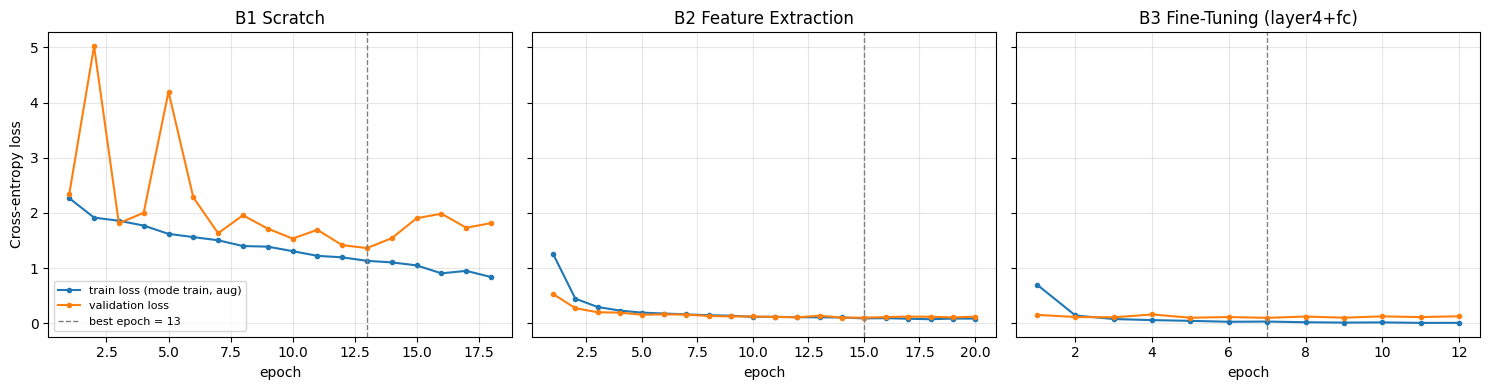

In [ ]:
LABELS = {"B1": "B1 Scratch", "B2": "B2 Feature Extraction", "B3": "B3 Fine-Tuning (layer4+fc)",
          "B4_noaug": "B4a tanpa augmentasi", "B4_aug": "B4b dengan augmentasi"}
def label(r):
    return LABELS.get(r, "B5 " + r.replace("B5_", ""))

def table_c1():
    rows = []
    for r, v in RUNS.items():
        s = v["summary"]
        rows.append({"Kode": r.replace("_", " "), "Strategi": label(r), "Arsitektur": s["arch"],
                     "Aug": "ya" if s["augment"] else "tidak",
                     "Trainable params": f"{s['trainable_params']:,}", "Learning rate": s["lr_per_group"],
                     "Epoch konvergen (best/jalan)": f"{s['best_epoch']}/{s['epochs_run']}",
                     "Waktu latih (s)": f"{s['train_time_sec']:.1f}",
                     "Val Acc": f"{s['val_acc']:.4f}", "Test Macro-F1": f"{s['test_macro_f1']:.4f}"})
    return pd.DataFrame(rows)

def df_to_md(df):
    cols = list(df.columns)
    lines = ["| " + " | ".join(cols) + " |", "|" + "|".join(["---"] * len(cols)) + "|"]
    for _, r in df.iterrows(): lines.append("| " + " | ".join(str(r[c]) for c in cols) + " |")
    return "\n".join(lines)

t_c1 = table_c1(); display(t_c1)
(OUT / "logs" / "table_C1.md").write_text(df_to_md(t_c1))

# Kurva training vs validation loss untuk B1, B2, B3
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, r in zip(axes, ["B1", "B2", "B3"]):
    h = RUNS[r]["history"]; be = RUNS[r]["summary"]["best_epoch"]
    ax.plot(h["epoch"], h["train_loss"], marker="o", ms=3, label="train loss (mode train, aug)")
    ax.plot(h["epoch"], h["val_loss"],   marker="o", ms=3, label="validation loss")
    ax.axvline(be, ls="--", c="gray", lw=1, label=f"best epoch = {be}")
    ax.set_title(label(r)); ax.set_xlabel("epoch"); ax.grid(alpha=.3)
axes[0].set_ylabel("Cross-entropy loss"); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT / "figures" / "curves_B1_B2_B3.png", dpi=200); plt.show()

## 8. C2: (data pendukung) = B4: augmentasi vs celah overfitting, dan B5: trade-off efisiensi

,Skenario,"Train Acc (eval, tanpa aug)",Val Acc,Gap (train-val),Val Loss,Test Acc,Test Macro-F1,Best epoch
0,B4a tanpa augmentasi,1.0000,0.9798,+0.0202,0.0851,0.9663,0.9664,4
1,B4b dengan augmentasi,0.9978,0.9764,+0.0214,0.1003,0.9663,0.9662,7


,Model,Trainable,Total params,Test Macro-F1,Waktu latih (s),Detik/epoch
0,resnet18 / scratch,"11,181,642","11,181,642",0.5368,211.6,11.8
1,resnet18 / feature_extraction,"5,130","11,181,642",0.9730,215.8,10.8
2,resnet18 / finetune,"8,398,858","11,181,642",0.9662,126.3,10.5
3,efficientnet_b0 / finetune,"1,142,202","4,020,358",0.9798,130.8,8.7
4,mobilenet_v3_small / finetune,"360,794","1,528,106",0.9664,104.5,7.0


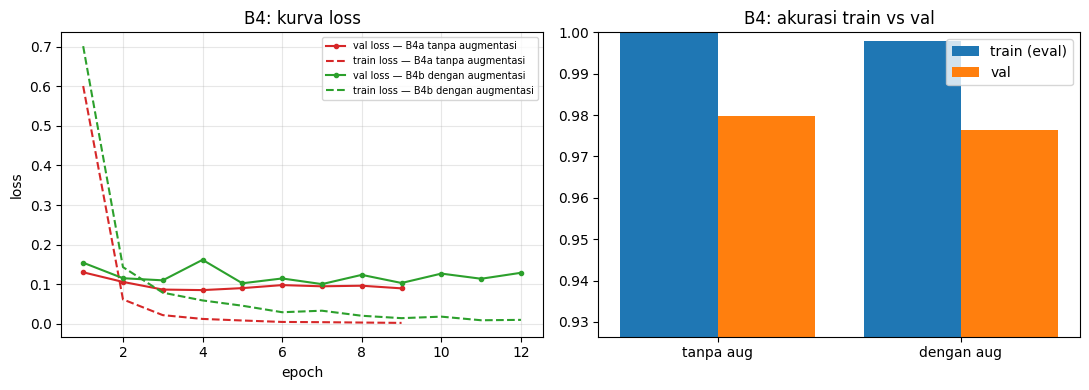

In [ ]:
def table_b4():
    rows = []
    for r in ("B4_noaug", "B4_aug"):
        s = RUNS[r]["summary"]
        rows.append({"Skenario": label(r), "Train Acc (eval, tanpa aug)": f"{s['train_acc_eval']:.4f}",
                     "Val Acc": f"{s['val_acc']:.4f}", "Gap (train-val)": f"{s['gap_train_val']:+.4f}",
                     "Val Loss": f"{s['val_loss']:.4f}", "Test Acc": f"{s['test_acc']:.4f}",
                     "Test Macro-F1": f"{s['test_macro_f1']:.4f}", "Best epoch": s["best_epoch"]})
    return pd.DataFrame(rows)

def table_b5():
    rows = []
    for r in ["B1", "B2", "B3"] + [k for k in RUNS if k.startswith("B5_")]:
        if r not in RUNS: continue
        s = RUNS[r]["summary"]
        rows.append({"Model": s["arch"] + " / " + s["strategy"], "Trainable": f"{s['trainable_params']:,}",
                     "Total params": f"{s['total_params']:,}", "Test Macro-F1": f"{s['test_macro_f1']:.4f}",
                     "Waktu latih (s)": f"{s['train_time_sec']:.1f}", "Detik/epoch": f"{s['sec_per_epoch']:.1f}"})
    return pd.DataFrame(rows)

t_b4, t_b5 = table_b4(), table_b5(); display(t_b4); display(t_b5)
(OUT / "logs" / "table_B4.md").write_text(df_to_md(t_b4)); (OUT / "logs" / "table_B5.md").write_text(df_to_md(t_b5))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for r, c in (("B4_noaug", "tab:red"), ("B4_aug", "tab:green")):
    h = RUNS[r]["history"]
    axes[0].plot(h["epoch"], h["val_loss"], c=c, marker="o", ms=3, label=f"val loss — {label(r)}")
    axes[0].plot(h["epoch"], h["train_loss"], c=c, ls="--", label=f"train loss — {label(r)}")
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("loss"); axes[0].legend(fontsize=7); axes[0].grid(alpha=.3); axes[0].set_title("B4: kurva loss")
xs = np.arange(2)
tr = [RUNS[r]["summary"]["train_acc_eval"] for r in ("B4_noaug", "B4_aug")]
va = [RUNS[r]["summary"]["val_acc"] for r in ("B4_noaug", "B4_aug")]
axes[1].bar(xs - .2, tr, .4, label="train (eval)"); axes[1].bar(xs + .2, va, .4, label="val")
axes[1].set_xticks(xs); axes[1].set_xticklabels(["tanpa aug", "dengan aug"]); axes[1].set_ylim(min(tr + va) - .05, 1.0)
axes[1].legend(); axes[1].set_title("B4: akurasi train vs val"); plt.tight_layout()
plt.savefig(OUT / "figures" / "b4_augmentation.png", dpi=200); plt.show()

## 9. C3: Failure analysis pada model terbaik (dipilih dari validation)

Ditampilkan 5–8 citra *test set* yang salah, diurutkan dari keyakinan tertinggi (kesalahan paling "percaya diri" paling informatif).

Model terbaik (val): B5_efficientnet_b0 | test errors: 6 dari 297


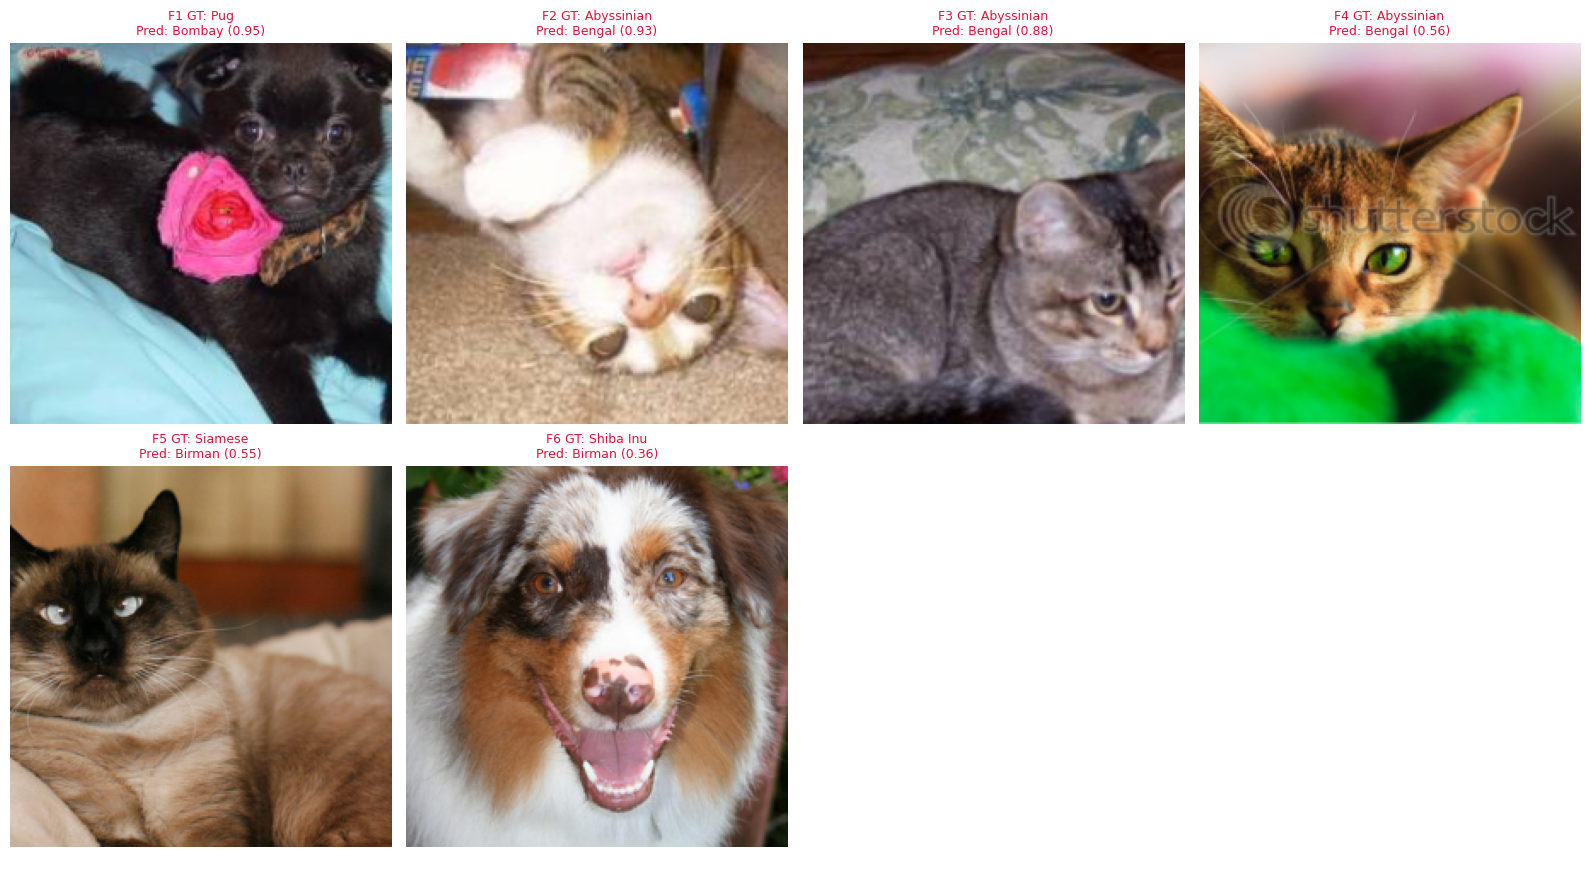

Top konfusi (jumlah, benar -> prediksi): [(np.int64(3), 'Abyssinian', 'Bengal'), (np.int64(1), 'Siamese', 'Birman'), (np.int64(1), 'Shiba Inu', 'Birman'), (np.int64(1), 'Pug', 'Bombay')]


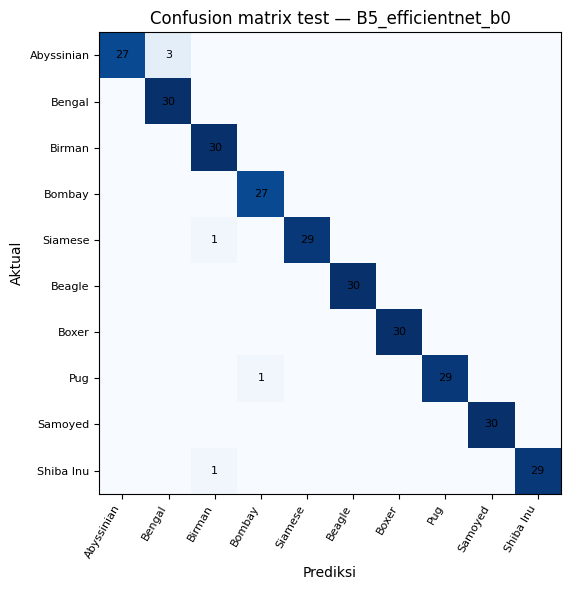

In [ ]:
best_id = pick_best(list(RUNS))
t = RUNS[best_id]["test"]; conf = t["probs"].max(1)
wrong = np.where(t["y_true"] != t["y_pred"])[0]
print(f"Model terbaik (val): {best_id} | test errors: {len(wrong)} dari {len(t['y_true'])}")
shown = list(wrong[np.argsort(-conf[wrong])][:8])
note = ""
if len(shown) < 5:
    top2 = np.sort(t["probs"], axis=1)[:, -2:]; margin = top2[:, 1] - top2[:, 0]
    correct = np.where(t["y_true"] == t["y_pred"])[0]
    shown += list(correct[np.argsort(margin[correct])][:5 - len(shown)])
    note = f"Hanya {len(wrong)} kesalahan; sisanya = prediksi BENAR dengan margin terkecil (bukan error)."
    print(note)

disp_tf = transforms.Compose([transforms.Resize(256), transforms.CenterCrop(224)])
rows = []
n = len(shown); cols = 4; nr = int(np.ceil(n / cols))
fig, axes = plt.subplots(nr, cols, figsize=(4 * cols, 4.4 * nr)); axes = np.atleast_1d(axes).ravel()
for k, (ax, i) in enumerate(zip(axes, shown), 1):
    gt, pr = SELECTED[t["y_true"][i]], SELECTED[t["y_pred"][i]]
    order = np.argsort(-t["probs"][i]); p1, p2 = order[0], order[1]
    ax.imshow(disp_tf(test_imgs[i])); ax.axis("off")
    ax.set_title(f"F{k} GT: {gt}\nPred: {pr} ({t['probs'][i][p1]:.2f})", fontsize=9, color="green" if gt == pr else "crimson")
    rows.append({"ID": f"F{k}", "test_index": int(i), "Ground truth": gt, "Prediksi": pr,
                 "Confidence": f"{t['probs'][i][p1]:.3f}", "Kandidat ke-2": f"{SELECTED[p2]} ({t['probs'][i][p2]:.3f})",
                 "Hipotesis penyebab": ""})
for ax in axes[n:]: ax.axis("off")
plt.tight_layout(); plt.savefig(OUT / "figures" / "failure_analysis.png", dpi=200); plt.show()

# Pasangan kelas yang paling sering tertukar
cm = confusion_matrix(t["y_true"], t["y_pred"], labels=range(NUM_CLASSES))
off = [(cm[a, b], SELECTED[a], SELECTED[b]) for a in range(NUM_CLASSES) for b in range(NUM_CLASSES) if a != b and cm[a, b] > 0]
print("Top konfusi (jumlah, benar -> prediksi):", sorted(off, reverse=True)[:6])
fig, ax = plt.subplots(figsize=(6.5, 6)); ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(NUM_CLASSES)); ax.set_yticks(range(NUM_CLASSES))
ax.set_xticklabels(SELECTED, rotation=60, ha="right", fontsize=8); ax.set_yticklabels(SELECTED, fontsize=8)
for a in range(NUM_CLASSES):
    for b in range(NUM_CLASSES):
        if cm[a, b]: ax.text(b, a, cm[a, b], ha="center", va="center", fontsize=8)
ax.set_xlabel("Prediksi"); ax.set_ylabel("Aktual"); ax.set_title(f"Confusion matrix test — {best_id}")
plt.tight_layout(); plt.savefig(OUT / "figures" / "confusion_matrix_best.png", dpi=200); plt.show()

In [ ]:
HIPOTESIS = {
    "F1": "Bulu hitam pekat dan atipikal untuk Pug; warna dominan menyerupai Bombay. Kesalahan sangat percaya diri (conf 0,945).",
    "F2": "Pose terbalik dengan perut putih menghadap kamera; ciri bulu ticked Abyssinian tidak terlihat. Pose ini jarang ada di data latih.",
    "F3": "Warna abu-abu kecokelatan dengan garis tabby (bukan cokelat kemerahan khas Abyssinian); wajah terpotong di tepi crop.",
    "F4": "Dua ras mirip secara visual (conf 0,559 vs 0,434); latar hijau jenuh dan watermark kemungkinan menjadi distraktor.",
    "F5": "Siamese dan Birman sama-sama berpola color point sehingga ambigu; skor Siamese 0,412 hampir menyamai prediksi.",
    "F6": "Citra tampak lebih mirip Australian Shepherd (merle) daripada Shiba Inu; kemungkinan label noise. Probabilitas tersebar (0,36 vs 0,24).",
}

failure_df["Hipotesis penyebab"] = failure_df["ID"].map(HIPOTESIS).fillna("[[ISI]]")
failure_df.to_csv(OUT / "logs" / "failure_cases.csv", index=False)
display(failure_df)

,ID,test_index,Ground truth,Prediksi,Confidence,Kandidat ke-2,Hipotesis penyebab
0,F1,234,Pug,Bombay,0.945,Pug (0.047),Bulu hitam pekat dan atipikal untuk Pug; warna...
1,F2,181,Abyssinian,Bengal,0.929,Abyssinian (0.056),Pose terbalik dengan perut putih menghadap kam...
2,F3,162,Abyssinian,Bengal,0.883,Abyssinian (0.112),Warna abu-abu kecokelatan dengan garis tabby (...
3,F4,260,Abyssinian,Bengal,0.559,Abyssinian (0.434),"Dua ras mirip secara visual (conf 0,559 vs 0,4..."
4,F5,21,Siamese,Birman,0.548,Siamese (0.412),Siamese dan Birman sama-sama berpola color poi...
5,F6,82,Shiba Inu,Birman,0.364,Beagle (0.240),Citra tampak lebih mirip Australian Shepherd (...


## 10. C5 (Eksplorasi) -> Grad-CAM pada `layer4`: sebelum vs sesudah fine-tuning

Sebelum = B2 (`layer4` identik dengan bobot ImageNet, hanya head yang dilatih sehingga Grad-CAM terhadap 10 kelas dimungkinkan). Sesudah = B3 (`layer4` telah disesuaikan).

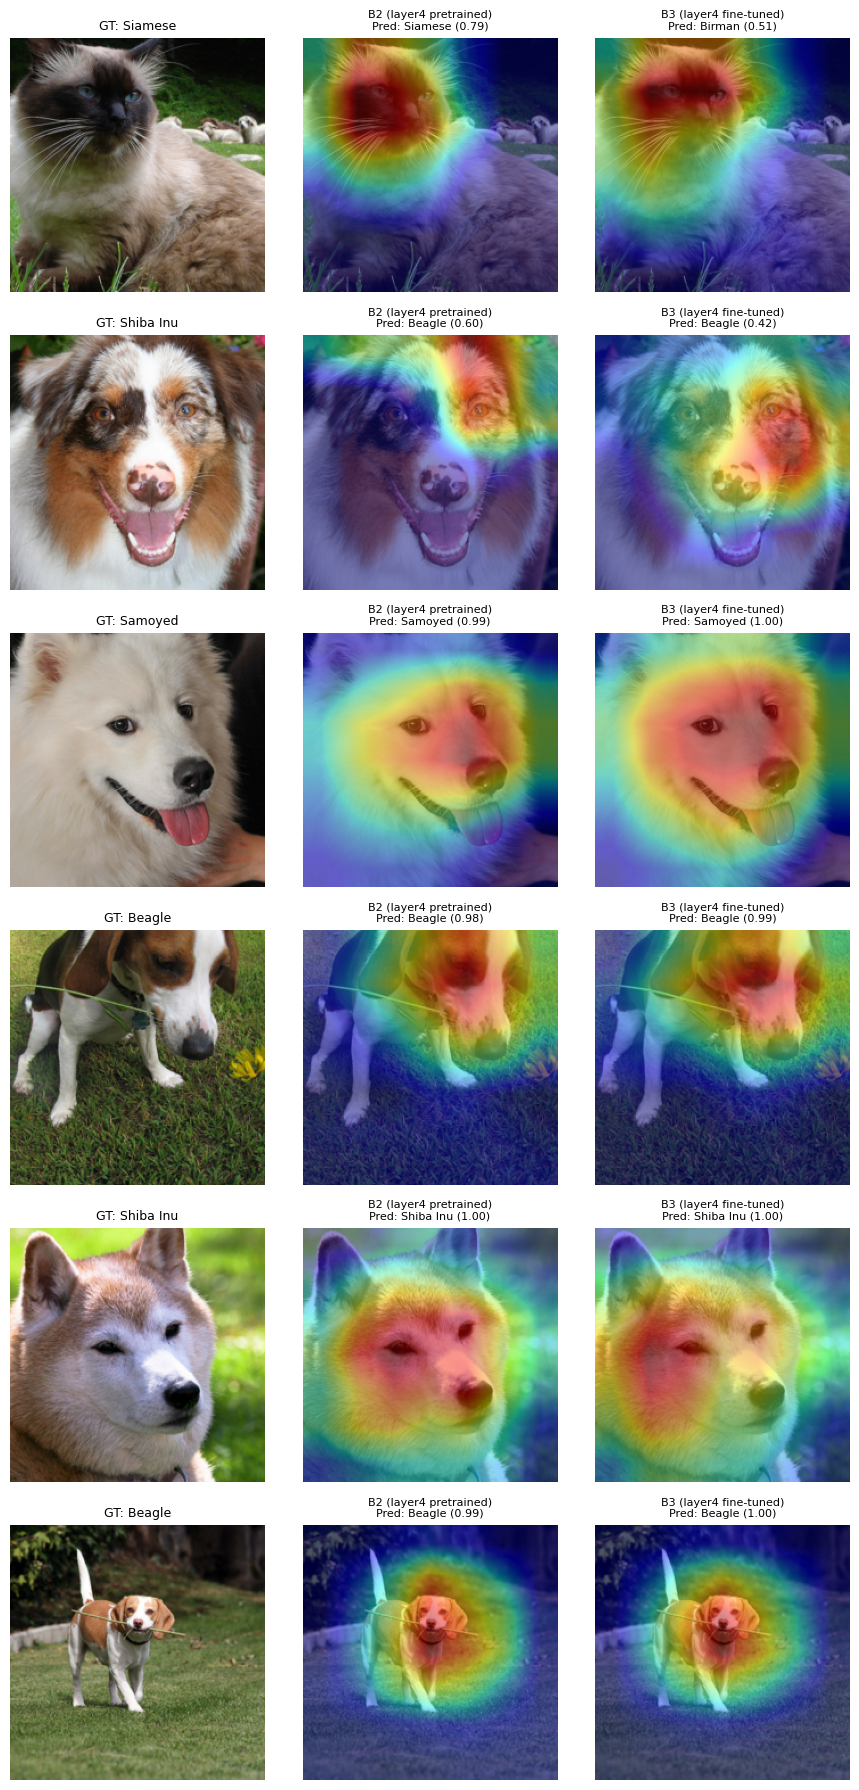

In [ ]:
def load_resnet(run_id):
    m, *_ = build_model("resnet18", "scratch")
    m.load_state_dict(torch.load(OUT / "checkpoints" / f"{run_id}.pt", map_location=DEVICE)); return m.eval()

def gradcam(model, x):
    feats = {}
    h = model.layer4.register_forward_hook(lambda m, i, o: feats.__setitem__("a", o))
    x = x.unsqueeze(0).to(DEVICE).requires_grad_(True)
    logits = model(x); cls = logits.argmax(1).item(); prob = logits.softmax(1)[0, cls].item()
    grads = torch.autograd.grad(logits[0, cls], feats["a"])[0]; h.remove()
    w = grads.mean(dim=(2, 3), keepdim=True)
    cam = F.relu((w * feats["a"]).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=(224, 224), mode="bilinear", align_corners=False)[0, 0]
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
    return cam.detach().cpu().numpy(), cls, prob

if "B2" in RUNS and "B3" in RUNS:
    m_before, m_after = load_resnet("B2"), load_resnet("B3")
    eval_tf = ARCH["resnet18"]["weights"].transforms()
    rng = np.random.RandomState(SEED)
    err = [i for i in range(len(test_y)) if RUNS["B3"]["test"]["y_true"][i] != RUNS["B3"]["test"]["y_pred"][i]][:2]
    ids = list(err) + list(rng.choice([i for i in range(len(test_y)) if i not in err], 4, replace=False))
    fig, axes = plt.subplots(len(ids), 3, figsize=(9, 3 * len(ids)))
    for r, i in enumerate(ids):
        x = eval_tf(test_imgs[i]); img = np.asarray(disp_tf(test_imgs[i]))
        axes[r, 0].imshow(img); axes[r, 0].set_title(f"GT: {SELECTED[test_y[i]]}", fontsize=9)
        for c, (m, nm) in enumerate(((m_before, "B2 (layer4 pretrained)"), (m_after, "B3 (layer4 fine-tuned)")), 1):
            cam, cls, p = gradcam(m, x)
            axes[r, c].imshow(img); axes[r, c].imshow(cam, cmap="jet", alpha=0.45)
            axes[r, c].set_title(f"{nm}\nPred: {SELECTED[cls]} ({p:.2f})", fontsize=8)
        for c in range(3): axes[r, c].axis("off")
    plt.tight_layout(); plt.savefig(OUT / "figures" / "gradcam_before_after.png", dpi=200); plt.show()
    del m_before, m_after

## 11. Paket Pengumpulan

In [ ]:
pack = Path("GSLC_SESI_5_2802559326_Fahrurrazi"); shutil.rmtree(pack, ignore_errors=True); pack.mkdir()
shutil.copytree(OUT / "logs", pack / "logs"); shutil.copytree(OUT / "figures", pack / "figures")
if (OUT / "Laporan_Tugas05.md").exists(): shutil.copy(OUT / "Laporan_Tugas05.md", pack)
shutil.make_archive("GSLC_SESI_5_2802559326_Fahrurrazi", "zip", pack); print("Dibuat: GSLC_SESI_5_2802559326_Fahrurrazi.zip")
try:
    from google.colab import files; files.download("GSLC_SESI_5_2802559326_Fahrurrazi.zip")
except Exception: pass

Dibuat: 2802559326_Fahrurrazi.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>